# RF and GaussianNB comparison

Use a stratified 30,000-row sample from the training split for 5-fold cross-validation and parameter selection. Keep the selected feature count and best parameters, then refit each final model on all 172,459 training rows. For k < 33, rank features by mutual information on all training rows. Evaluate the 43,115-row held-out test set once per model.

Average precision (AP) is the main metric. ROC-AUC, accuracy, precision, recall, F1, and processing times are also recorded. Test results are exploratory and are not used to change settings.

## 1. Imports, data, and shared split

In [1]:
from pathlib import Path
import sys
import time
import platform

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import (
    ParameterGrid,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "preprocessing.py").exists() else cwd.parent
assert (repo_root / "src" / "preprocessing.py").exists(), (
    "Open this notebook from the project root or notebooks/ directory."
)
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import NUMERIC_COLUMNS, build_preprocessor, prepare_xy, select_features

data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    import subprocess
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)

df = pd.read_csv(data_path, skipinitialspace=True)
X, y = prepare_xy(df)
X = select_features(X, include_migration=False)  # Baseline: 33 original features

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=42
)
folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X_dev, y_dev))

FEATURE_COUNTS = [5, 10, 15, 17, 20, 25, 33]
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
print(f"Original features: {X.shape[1]}")
print(f"Training rows: {len(X_train):,}; held-out test rows: {len(X_test):,}")
print(f"CV sample rows: {len(X_dev):,}; positive rate: {y_dev.mean():.4f}")
print(f"CV folds: {len(folds)}; feature counts: {FEATURE_COUNTS}")

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4
Original features: 33
Training rows: 172,459; held-out test rows: 43,115
CV sample rows: 30,000; positive rate: 0.0861
CV folds: 5; feature counts: [5, 10, 15, 17, 20, 25, 33]


## 2. MI ranking within each training fold

MI ranks the original features using only the training part of each fold. The validation rows are not used to select features.

In [2]:
def rank_features_by_mi(X_fit, y_fit):
    # Rank original features using only this fold's training rows.
    work = X_fit.copy()
    numeric = [column for column in NUMERIC_COLUMNS if column in work.columns]
    categorical = [column for column in work.columns if column not in numeric]

    if numeric:
        work[numeric] = SimpleImputer(strategy="median").fit_transform(work[numeric])
    if categorical:
        encoded = SimpleImputer(
            strategy="constant", fill_value="Missing"
        ).fit_transform(work[categorical])
        encoded = OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1
        ).fit_transform(encoded)
        work[categorical] = encoded

    discrete = [column in categorical for column in work.columns]
    scores = mutual_info_classif(
        work, y_fit, discrete_features=discrete,
        random_state=42, n_neighbors=3,
    )
    return (
        pd.DataFrame({"feature": work.columns, "MI": scores})
        .sort_values(["MI", "feature"], ascending=[False, True])
        .reset_index(drop=True)
    )

# Small preview; the actual CV ranks features within each fold.
display(rank_features_by_mi(X_dev.iloc[:1_000], y_dev.iloc[:1_000]).head(10))

,feature,MI
0,detailed_occupation_recode,0.086945
1,major_occupation_code,0.061866
2,detailed_industry_recode,0.060013
3,weeks_worked_in_year,0.049292
4,education,0.048986
5,major_industry_code,0.039343
6,sex,0.034031
7,class_of_worker,0.028454
8,tax_filer_stat,0.028141
9,num_persons_worked_for_employer,0.023196


## 3. Evaluation functions and initial model comparison

In [3]:
def make_model(model_name, params=None):
    params = {} if params is None else dict(params)
    if model_name == "Random Forest":
        settings = {"n_estimators": 200, "random_state": 42, "n_jobs": 1}
        settings.update(params)
        return RandomForestClassifier(**settings)
    if model_name == "GaussianNB":
        settings = {"var_smoothing": 1e-9}
        settings.update(params)
        return GaussianNB(**settings)
    raise ValueError(f"Unknown model: {model_name}")


def run_cv(model_name, k, params=None):
    rows = []
    for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):
        X_fit, y_fit = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
        X_valid, y_valid = X_dev.iloc[valid_idx], y_dev.iloc[valid_idx]

        mi_seconds = 0.0
        if k == X_dev.shape[1]:
            selected = list(X_fit.columns)
        else:
            started = time.perf_counter()
            ranking = rank_features_by_mi(X_fit, y_fit)
            selected = ranking["feature"].head(k).tolist()
            mi_seconds = time.perf_counter() - started

        X_fit_k, X_valid_k = X_fit[selected], X_valid[selected]
        preprocessor = build_preprocessor(X_fit_k, log_money=False)
        started = time.perf_counter()
        Z_fit = preprocessor.fit_transform(X_fit_k)
        Z_valid = preprocessor.transform(X_valid_k)
        if model_name == "GaussianNB":
            if hasattr(Z_fit, "toarray"):
                Z_fit, Z_valid = Z_fit.toarray(), Z_valid.toarray()
        preprocessing_seconds = time.perf_counter() - started

        model = make_model(model_name, params)
        started = time.perf_counter()
        model.fit(Z_fit, y_fit)
        fit_seconds = time.perf_counter() - started

        started = time.perf_counter()
        probability = model.predict_proba(Z_valid)[:, 1]
        predict_seconds = time.perf_counter() - started
        predicted = (probability >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_valid, predicted, labels=[0, 1]
        ).ravel()

        rows.append({
            "model": model_name, "k": k, "fold": fold_number,
            "AP": average_precision_score(y_valid, probability),
            "ROC_AUC": roc_auc_score(y_valid, probability),
            "Accuracy": accuracy_score(y_valid, predicted),
            "Precision": precision_score(y_valid, predicted, zero_division=0),
            "Recall": recall_score(y_valid, predicted, zero_division=0),
            "F1": f1_score(y_valid, predicted, zero_division=0),
            "MI_seconds": mi_seconds,
            "preprocessing_seconds": preprocessing_seconds,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        })
    return pd.DataFrame(rows)


all_folds = []
for model_name in ["Random Forest", "GaussianNB"]:
    for k in FEATURE_COUNTS:
        print(f"Running {model_name}, {k} features ...", flush=True)
        all_folds.append(run_cv(model_name, k))

fold_results = pd.concat(all_folds, ignore_index=True)
summary = (
    fold_results.groupby(["model", "k"])
    .agg(
        AP_mean=("AP", "mean"), AP_sd=("AP", "std"),
        ROC_AUC_mean=("ROC_AUC", "mean"),
        Accuracy_mean=("Accuracy", "mean"),
        Precision_mean=("Precision", "mean"),
        Recall_mean=("Recall", "mean"), F1_mean=("F1", "mean"),
        MI_seconds_mean=("MI_seconds", "mean"),
        preprocessing_seconds_mean=("preprocessing_seconds", "mean"),
        fit_seconds_mean=("fit_seconds", "mean"),
        predict_seconds_mean=("predict_seconds", "mean"),
    )
    .reset_index()
)
display(summary.round(4))

Running Random Forest, 5 features ...


Running Random Forest, 10 features ...


Running Random Forest, 15 features ...


Running Random Forest, 17 features ...


Running Random Forest, 20 features ...


Running Random Forest, 25 features ...


... (5 outputs left out)

Running GaussianNB, 20 features ...


Running GaussianNB, 25 features ...


Running GaussianNB, 33 features ...


,model,k,AP_mean,AP_sd,ROC_AUC_mean,Accuracy_mean,Precision_mean,Recall_mean,F1_mean,MI_seconds_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean
0,GaussianNB,5,0.1676,0.0350,0.7359,0.4229,0.1233,0.9327,0.2178,0.5464,0.0299,0.0142,0.0036
1,GaussianNB,10,0.1423,0.0153,0.7029,0.4057,0.1216,0.9481,0.2156,0.5584,0.0479,0.0153,0.0042
2,GaussianNB,15,0.1324,0.0036,0.6865,0.4179,0.1254,0.9628,0.2218,0.5316,0.0647,0.0170,0.0044
3,GaussianNB,17,0.1332,0.0036,0.6886,0.4216,0.1260,0.9628,0.2229,0.5492,0.0724,0.0180,0.0048
4,GaussianNB,20,0.1161,0.0062,0.6371,0.3430,0.1132,0.9671,0.2027,0.5158,0.0842,0.0382,0.0072
5,GaussianNB,25,0.1037,0.0026,0.5903,0.2757,0.1028,0.9582,0.1856,0.5510,0.1091,0.0468,0.0079
6,GaussianNB,33,0.1039,0.0022,0.5910,0.2797,0.1031,0.9559,0.1861,0.0000,0.1502,0.0360,0.0081
7,Random Forest,5,0.4194,0.0360,0.8381,0.9175,0.5424,0.2721,0.3621,0.5717,0.0295,4.9549,0.1216
8,Random Forest,10,0.5043,0.0243,0.8796,0.9231,0.5830,0.3742,0.4554,0.5499,0.0449,8.4543,0.1363
9,Random Forest,15,0.5726,0.0159,0.9069,0.9306,0.6703,0.3843,0.4878,0.5900,0.0974,10.1454,0.1448


## 4. Compare AP and computation time

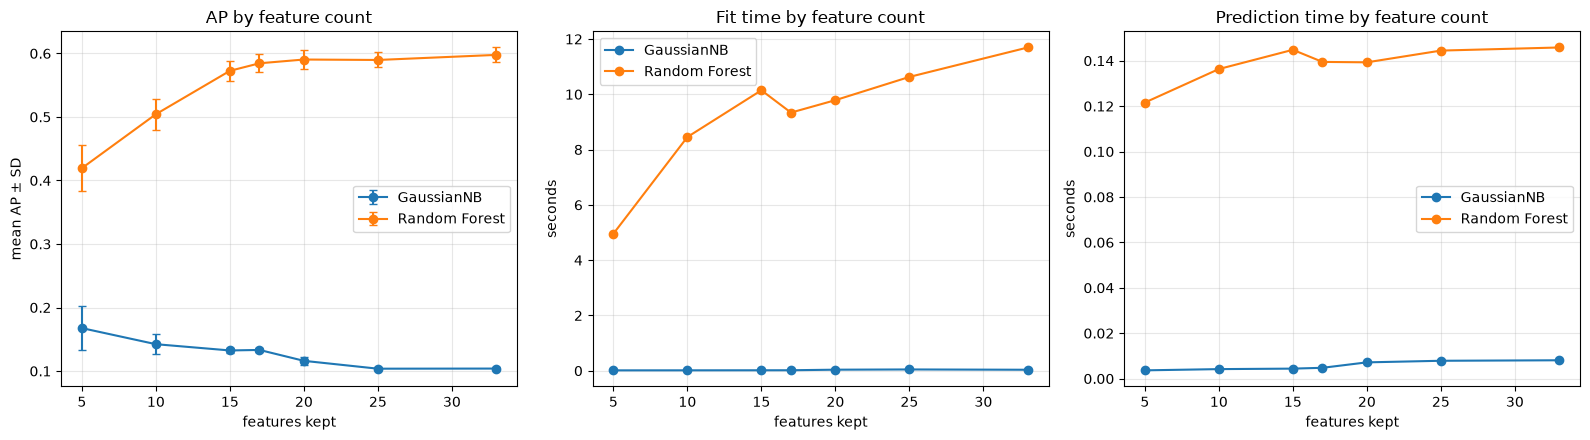

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for model_name, group in summary.groupby("model"):
    group = group.sort_values("k")
    axes[0].errorbar(group["k"], group["AP_mean"], yerr=group["AP_sd"], marker="o", capsize=3, label=model_name)
    axes[1].plot(group["k"], group["fit_seconds_mean"], marker="o", label=model_name)
    axes[2].plot(group["k"], group["predict_seconds_mean"], marker="o", label=model_name)
axes[0].set(title="AP by feature count", xlabel="features kept", ylabel="mean AP ± SD")
axes[1].set(title="Fit time by feature count", xlabel="features kept", ylabel="seconds")
axes[2].set(title="Prediction time by feature count", xlabel="features kept", ylabel="seconds")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Hyperparameter search

The parameter search compares a small set of settings on the same folds. The table below shows the tested settings and scores.

In [5]:
chosen_k = (
    summary.sort_values(["model", "AP_mean", "k"], ascending=[True, False, True])
    .groupby("model", as_index=False).first()[["model", "k"]]
    .set_index("model")["k"].astype(int).to_dict()
)
print("Feature count chosen from initial CV AP:", chosen_k)

parameter_grids = {
    "Random Forest": {
        "n_estimators": [200, 400],
        "max_depth": [None, 20],
        "min_samples_leaf": [1, 5],
    },
    "GaussianNB": {"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]},
}

tuning_rows = []
for model_name, grid in parameter_grids.items():
    for params in ParameterGrid(grid):
        print(f"Tuning {model_name}: {params}", flush=True)
        scores = run_cv(model_name, chosen_k[model_name], params=params)
        tuning_rows.append({
            "model": model_name,
            "k": chosen_k[model_name],
            "params": params,
            "AP_mean": scores["AP"].mean(),
            "AP_sd": scores["AP"].std(),
            "ROC_AUC_mean": scores["ROC_AUC"].mean(),
            "F1_mean": scores["F1"].mean(),
            "fit_seconds_mean": scores["fit_seconds"].mean(),
            "predict_seconds_mean": scores["predict_seconds"].mean(),
        })

tuning_summary = pd.DataFrame(tuning_rows)
best_tuning = (
    tuning_summary.sort_values(["model", "AP_mean"], ascending=[True, False])
    .groupby("model", as_index=False).first()
)
display(tuning_summary.sort_values(["model", "AP_mean"], ascending=[True, False]).round(4))
print("Selected settings by CV AP:")
display(best_tuning[["model", "k", "params", "AP_mean", "AP_sd"]])

Feature count chosen from initial CV AP: {'GaussianNB': 5, 'Random Forest': 33}
Tuning Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


Tuning Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}


Tuning Random Forest: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}


Tuning Random Forest: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}


Tuning Random Forest: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}


Tuning Random Forest: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 400}


... (5 outputs left out)

Tuning GaussianNB: {'var_smoothing': 1e-06}


,model,k,params,AP_mean,AP_sd,ROC_AUC_mean,F1_mean,fit_seconds_mean,predict_seconds_mean
11,GaussianNB,5,{'var_smoothing': 1e-06},0.2241,0.0152,0.8000,0.2760,0.0103,0.0027
10,GaussianNB,5,{'var_smoothing': 1e-07},0.2082,0.0138,0.7887,0.2250,0.0103,0.0027
9,GaussianNB,5,{'var_smoothing': 1e-08},0.1872,0.0336,0.7621,0.2192,0.0104,0.0028
8,GaussianNB,5,{'var_smoothing': 1e-09},0.1676,0.0350,0.7359,0.2178,0.0144,0.0033
5,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.6238,0.0174,0.9218,0.4191,12.1968,0.2038
4,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.6222,0.0171,0.9212,0.4191,6.1633,0.1042
2,Random Forest,33,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.6194,0.0184,0.9228,0.3745,4.7604,0.1053
3,Random Forest,33,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.6191,0.0192,0.9233,0.3780,9.7056,0.2188
7,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 5, 'n_es...",0.6183,0.0192,0.9221,0.3533,7.6351,0.1904
6,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 5, 'n_es...",0.6175,0.0189,0.9219,0.3538,3.8227,0.0942


Selected settings by CV AP:


,model,k,params,AP_mean,AP_sd
0,GaussianNB,5,{'var_smoothing': 1e-06},0.224140,0.015238
1,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.623788,0.017416


## 6. One-time held-out test evaluation

After selecting the settings, each model is refit on all 172,459 training rows and evaluated once on the 43,115-row held-out test set. For k < 33, MI ranking uses all training rows. The test results are not used to change the settings. The confusion matrices use a 0.5 threshold.

In [6]:
final_rows = []
final_predictions = {}
final_models = {}
final_fit_rows = {}

assert len(X_train) == 172_459
assert len(X_test) == 43_115

for _, choice in best_tuning.iterrows():
    model_name = choice["model"]
    k = int(choice["k"])
    params = choice["params"]

    # Reuse CV-selected k and parameters. Rank on all training rows for k < 33.
    mi_seconds = 0.0
    if k == X_train.shape[1]:
        selected = list(X_train.columns)
    else:
        started = time.perf_counter()
        selected = rank_features_by_mi(X_train, y_train)["feature"].head(k).tolist()
        mi_seconds = time.perf_counter() - started

    X_train_k, X_test_k = X_train[selected], X_test[selected]
    preprocessor = build_preprocessor(X_train_k, log_money=False)
    started = time.perf_counter()
    Z_train = preprocessor.fit_transform(X_train_k)
    Z_test = preprocessor.transform(X_test_k)
    if model_name == "GaussianNB" and hasattr(Z_train, "toarray"):
        Z_train, Z_test = Z_train.toarray(), Z_test.toarray()
    preprocessing_seconds = time.perf_counter() - started

    model = make_model(model_name, params)
    started = time.perf_counter()
    model.fit(Z_train, y_train)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    probability = model.predict_proba(Z_test)[:, 1]
    predict_seconds = time.perf_counter() - started
    predicted = (probability >= 0.5).astype(int)
    final_models[model_name] = (model, preprocessor, selected)
    final_predictions[model_name] = (probability, predicted)
    final_fit_rows[model_name] = len(X_train)
    final_rows.append({
        "model": model_name, "k": k, "params": params,
        "training_rows": len(X_train), "test_rows": len(X_test),
        "MI_seconds": mi_seconds,
        "preprocessing_seconds": preprocessing_seconds,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "AP": average_precision_score(y_test, probability),
        "ROC_AUC": roc_auc_score(y_test, probability),
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
    })

test_summary = pd.DataFrame(final_rows)
display(test_summary.round(4))

,model,k,params,training_rows,test_rows,MI_seconds,preprocessing_seconds,fit_seconds,predict_seconds,AP,ROC_AUC,Accuracy,Precision,Recall,F1
0,GaussianNB,5,{'var_smoothing': 1e-06},172459,43115,4.5828,0.1752,0.1054,0.0218,0.3046,0.8344,0.7334,0.2224,0.8392,0.3516
1,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",172459,43115,0.0000,1.0169,180.1792,1.1779,0.6583,0.9294,0.9356,0.8411,0.3108,0.4539


## 7. Confusion matrices and ROC curves

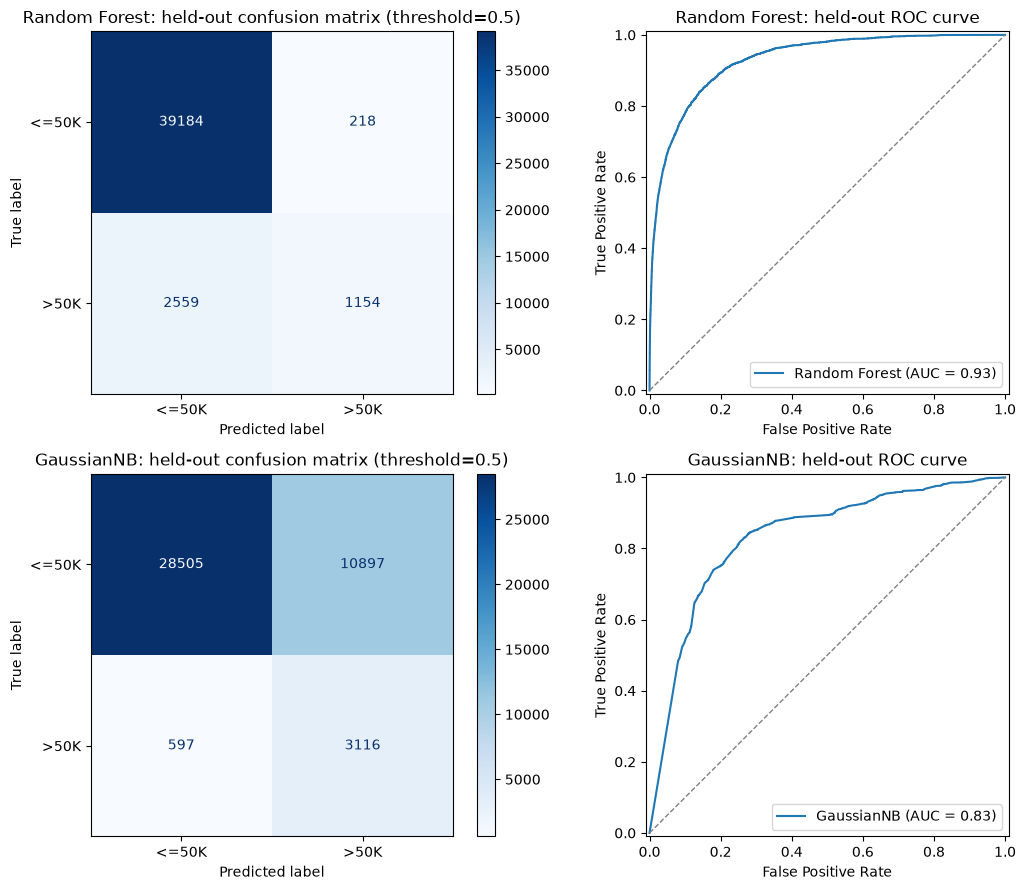

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, model_name in enumerate(["Random Forest", "GaussianNB"]):
    probability, predicted = final_predictions[model_name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1],
        display_labels=["<=50K", ">50K"],
        cmap="Blues", values_format="d", ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{model_name}: held-out confusion matrix (threshold=0.5)")
    RocCurveDisplay.from_predictions(y_test, probability, name=model_name, ax=axes[row, 1])
    axes[row, 1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
    axes[row, 1].set_title(f"{model_name}: held-out ROC curve")
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
fig.tight_layout()
plt.show()

## 8. Final checks

In [8]:
assert len(X_train) == 172_459
assert len(X_test) == 43_115
assert X.shape[1] == 33
assert len(X_dev) == 30_000
assert len(folds) == 5
assert len(fold_results) == 70
assert fold_results.groupby(["model", "k"]).size().eq(5).all()
assert len(tuning_summary) == 12
assert set(test_summary["model"]) == {"Random Forest", "GaussianNB"}
assert test_summary["training_rows"].eq(172_459).all()
assert test_summary["test_rows"].eq(43_115).all()
assert final_fit_rows == {"Random Forest": 172_459, "GaussianNB": 172_459}
assert all(len(final_predictions[name][0]) == 43_115 for name in final_predictions)
print("Final checks passed.")
print(f"CV result rows: {len(fold_results):,} (expected 70)")
print(f"Tuning configurations: {len(tuning_summary):,} (expected 12)")
print(f"Final fit rows per model: {final_fit_rows}")
print(f"Held-out test rows per model: {len(X_test):,}")
total_seconds = time.perf_counter() - experiment_started
print(f"Total execution time: {total_seconds:.2f} seconds")

Final checks passed.
CV result rows: 70 (expected 70)
Tuning configurations: 12 (expected 12)
Final fit rows per model: {'GaussianNB': 172459, 'Random Forest': 172459}
Held-out test rows per model: 43,115
Total execution time: 989.33 seconds
